# CornSight — Notebook 2: From Corn Maps to Market Intelligence
**Team:** Akane Eto, Alonso Manchego, Divisha Chellani, Nil Gaziyeva, Tsai-Ling Chen
**Professor:** Kurnicki — Hult International Business School
**Project:** CornSight — using satellite imagery and an AI agent to get an early read on the US corn harvest

**Who this is for:** grain trading desks and agricultural lenders.
**The problem:** USDA's final corn yields come out months after the growing season. By then, traders and lenders have already made their decisions. We wanted to see whether satellite imagery, combined with an AI agent, could flag struggling states much earlier.
**Our assumptions:** we use 2022 as a backtest year, use only peak-season (July–August) photos, and focus on major corn states (at least 300 million bushels a year on average, 2017–21).

In Notebook 1 we trained the Prithvi satellite model and produced `chip_results.csv`: for 771 satellite images across the US, how much corn is planted and how healthy it looks. This notebook turns that into business intelligence:

| Part | What we do |
|---|---|
| **A** | Work out which **state** each satellite image is in, and summarise corn acreage and corn health by state |
| **B** | Pull official **USDA** corn yields by state (2017–2022) and find which states had a bad 2022 |
| **C** | Pull **2022 corn futures prices** and measure how the market moved on USDA report days |
| **D** | Store everything in **MongoDB**: images, states, USDA data, prices, reports and charts |
| **E** | **Analysis:** did the satellite see what USDA confirmed later, and what is that worth? |
| **F** | **AI agent:** an open LLM from Hugging Face (Qwen3-4B) that queries MongoDB with tools, reasons over the data, and writes briefs for a trading desk and an agricultural lender. The briefs are saved back to MongoDB |

**To run:**
1. Set `Runtime > Change runtime type > T4 GPU` (only Part F needs it).
2. Add `MONGODB_URI` and `NASS_API_KEY` to Colab **Secrets** (left sidebar) and switch on notebook access. We deliberately kept our credentials out of the notebook.
3. Notebook 1's results are read directly from our public GitHub repo [`AlonsoManchego/cornsight`](https://github.com/AlonsoManchego/cornsight/tree/main/training_outputs), so no Google Drive is needed.

A full run takes about 15–20 minutes, most of it Part F downloading the 8 GB language model.

## Setup — install packages, load secrets, connect to MongoDB

In [1]:
!pip install -q pymongo yfinance reverse_geocoder 'transformers>=4.56'

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, json, re, time, io, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

try:                                   # on Colab: read keys from Secrets
    from google.colab import userdata
    MONGODB_URI = userdata.get("MONGODB_URI")
    NASS_API_KEY = userdata.get("NASS_API_KEY")
except ImportError:                    # running locally: read keys from a .env file
    from dotenv import load_dotenv
    load_dotenv(".env")
    MONGODB_URI = os.environ["MONGODB_URI"]
    NASS_API_KEY = os.environ["NASS_API_KEY"]

# Notebook 1's results are in our public GitHub repo
GITHUB_REPO = "AlonsoManchego/cornsight"
TRAINING_URL = f"https://raw.githubusercontent.com/{GITHUB_REPO}/main/training_outputs"

# charts and brief files are saved locally; all the data goes to MongoDB
OUT_DIR = "/content/cornsight_outputs" if os.path.exists("/content") else "./cornsight_outputs"
CHART_DIR = os.path.join(OUT_DIR, "pipeline_charts")
os.makedirs(CHART_DIR, exist_ok=True)
print("Training results from:", TRAINING_URL)
print("chip_results.csv reachable:", requests.head(f"{TRAINING_URL}/chip_results.csv").status_code == 200)
print("Secrets loaded:", bool(MONGODB_URI), bool(NASS_API_KEY))

Training results from: https://raw.githubusercontent.com/AlonsoManchego/cornsight/main/training_outputs
chip_results.csv reachable: True
Secrets loaded: True True


In [3]:
from pymongo import MongoClient, ASCENDING
import gridfs

client = MongoClient(MONGODB_URI, serverSelectionTimeoutMS=20000)
client.admin.command("ping")
db = client["cornsight"]
print("Connected to MongoDB Atlas — database 'cornsight'")
print("Existing collections:", db.list_collection_names())

def save_collection(name, records, key=None):
    """Replace a MongoDB collection with fresh records (safe to re-run)."""
    db[name].delete_many({})
    if records:
        db[name].insert_many(records)
    if key:
        db[name].create_index([(key, ASCENDING)])
    print(f"  {name}: {db[name].count_documents({})} documents")

def clean(df):
    """Pandas -> plain Python dicts MongoDB can store (NaN -> None, numpy -> float/int)."""
    return json.loads(df.to_json(orient="records"))

Connected to MongoDB Atlas — database 'cornsight'
Existing collections: ['usda_yields', 'corn_prices', 'chips', 'briefs', 'images.chunks', 'model_metrics', 'states', 'wasde_reports', 'images.files']


---
## Part A — Satellite results by state
Each satellite image ("chip") has a latitude and longitude, so we look up which US state it's in and summarise by state:
- **Corn share:** the % of land the model sees as corn, a proxy for planted acreage.
- **Corn health (peak season):** the average NDVI of corn pixels in photos taken in **July–August**, when corn is at its greenest. NDVI runs from 0 (bare soil) to about 0.9 (dense, healthy crop). We leave out March and September photos: there's either no crop yet or it's being harvested, so they'd be misleading.

In [4]:
import reverse_geocoder as rg

chips = pd.read_csv(f"{TRAINING_URL}/chip_results.csv")          # Notebook 1's results, loaded from GitHub
geo = rg.search(list(zip(chips.lat, chips.lon)), mode=1)
chips["country"] = [g["cc"] for g in geo]
chips["state"] = [g["admin1"].upper() for g in geo]
chips = chips[chips.country == "US"].copy()

def peak_ndvi(row):
    """Highest corn NDVI among photos taken in July or August (None if no such photo / no corn)."""
    vals = [row[f"corn_ndvi_{t}"] for t in (1, 2, 3)
            if pd.to_datetime(row[f"date_{t}"]).month in (7, 8) and pd.notna(row[f"corn_ndvi_{t}"])]
    return max(vals) if vals else np.nan

chips["corn_health_peak"] = chips.apply(peak_ndvi, axis=1)
print(f"{len(chips)} US chips in {chips.state.nunique()} states; "
      f"{chips.corn_health_peak.notna().sum()} have a peak-season photo with corn")

states = chips.groupby("state").agg(
    chips=("chip_id", "count"),
    corn_share_pred=("corn_share_pred", "mean"),
    corn_share_true=("corn_share_true", "mean"),
    corn_health_peak=("corn_health_peak", "mean"),
    peak_photos=("corn_health_peak", "count"),
).reset_index()
states.sort_values("corn_share_pred", ascending=False).head(10).round(3)

Loading formatted geocoded file...
770 US chips in 39 states; 291 have a peak-season photo with corn


,state,chips,corn_share_pred,corn_share_true,corn_health_peak,peak_photos
10,IOWA,22,0.233,0.225,0.876,14
14,MARYLAND,4,0.224,0.240,0.859,1
4,DELAWARE,5,0.202,0.215,NaN,0
9,INDIANA,27,0.190,0.197,0.851,10
20,NEBRASKA,13,0.182,0.222,0.801,9
16,MINNESOTA,18,0.173,0.188,0.867,11
38,WISCONSIN,57,0.172,0.199,0.816,28
8,ILLINOIS,39,0.167,0.190,0.873,21
31,SOUTH DAKOTA,29,0.167,0.188,0.819,26
35,VIRGINIA,1,0.166,0.178,NaN,0


---
## Part B — Official USDA corn yields (2017–2022)
This comes from the USDA's **NASS Quick Stats API**. Yield is bushels of corn per acre. We compare each state's 2022 yield with its own 2017–2021 average to see who had a bad year. 2022 had a drought in the western Corn Belt.

The USDA API can be very slow, so we download the data **once** and store it in MongoDB; later runs read it from there. Set `REFRESH_USDA = True` to force a fresh download.

In [5]:
REFRESH_USDA = False
NASS_URL = "https://quickstats.nass.usda.gov/api/api_GET/"
USDA_SERIES = {
    "yield_bu_acre":   "CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",
    "acres_harvested": "CORN, GRAIN - ACRES HARVESTED",
    "production_bu":   "CORN, GRAIN - PRODUCTION, MEASURED IN BU",
}

def fetch_nass(short_desc, tries=3):
    params = {"key": NASS_API_KEY, "short_desc": short_desc, "agg_level_desc": "STATE",
              "source_desc": "SURVEY", "reference_period_desc": "YEAR",
              "year__GE": 2017, "year__LE": 2022, "format": "JSON"}
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(NASS_URL, params=params, timeout=300)
            r.raise_for_status()
            return pd.DataFrame(r.json()["data"])
        except Exception as e:
            print(f"   attempt {attempt} failed ({type(e).__name__}); retrying..." if attempt < tries else f"   giving up: {e}")
            time.sleep(5)
    raise RuntimeError("USDA API not responding — try again in a few minutes")

if REFRESH_USDA or db.usda_yields.count_documents({}) == 0:
    print("Downloading from the USDA API (can take 1–3 min)...")
    frames = []
    for col, desc in USDA_SERIES.items():
        d = fetch_nass(desc)
        d = d[d.prodn_practice_desc == "ALL PRODUCTION PRACTICES"]
        d["value"] = pd.to_numeric(d.Value.astype(str).str.replace(",", ""), errors="coerce")
        frames.append(d[["state_name", "year", "value"]].assign(metric=col))
    usda_long = pd.concat(frames)
    usda_long["year"] = usda_long.year.astype(int)
    save_collection("usda_yields", clean(usda_long), key="state_name")
else:
    print("Reading USDA data stored in MongoDB")
usda_long = pd.DataFrame(list(db.usda_yields.find({}, {"_id": 0})))

usda = usda_long.pivot_table(index="state_name", columns=["metric", "year"], values="value")
usda_state = pd.DataFrame({
    "usda_yield_2022": usda[("yield_bu_acre", 2022)],
    "usda_yield_avg_17_21": usda["yield_bu_acre"][[2017, 2018, 2019, 2020, 2021]].mean(axis=1),
    "production_2022_bu": usda[("production_bu", 2022)],
    "production_avg_17_21_bu": usda["production_bu"][[2017, 2018, 2019, 2020, 2021]].mean(axis=1),
    "acres_harvested_2022": usda[("acres_harvested", 2022)],
})
usda_state["yield_change_pct"] = (usda_state.usda_yield_2022 / usda_state.usda_yield_avg_17_21 - 1) * 100
usda_state = usda_state.reset_index().rename(columns={"state_name": "state"})
print(f"USDA yields for {len(usda_state)} states")
usda_state.sort_values("yield_change_pct").head(8).round(1)

Reading USDA data stored in MongoDB
USDA yields for 42 states


,state,usda_yield_2022,usda_yield_avg_17_21,production_2022_bu,production_avg_17_21_bu,acres_harvested_2022,yield_change_pct
22,NEW JERSEY,114.0,156.4,6612000.0,10665000.0,58000.0,-27.1
35,TEXAS,95.0,127.4,152950000.0,251406000.0,1610000.0,-25.4
0,ALABAMA,118.0,158.2,34220000.0,44100000.0,290000.0,-25.4
34,TENNESSEE,130.0,171.2,102050000.0,138338000.0,785000.0,-24.1
12,KANSAS,115.0,133.4,510600000.0,729312000.0,4440000.0,-13.8
13,KENTUCKY,156.0,179.6,207480000.0,239718000.0,1330000.0,-13.1
24,NEW YORK,142.0,160.4,80230000.0,87763000.0,565000.0,-11.5
33,SOUTH DAKOTA,132.0,149.0,661320000.0,705340000.0,5010000.0,-11.4


---
## Part C — Corn futures and USDA report days
We use corn futures (`ZC=F`, traded in Chicago and priced in **cents per bushel**; one contract is 5,000 bushels). Every month the USDA publishes its **WASDE** report (World Agricultural Supply and Demand Estimates) with an updated crop forecast. Traders watch it closely because a surprise moves prices immediately.

Here we measure how much corn prices moved on WASDE days compared with ordinary trading days.

In [6]:
import yfinance as yf

# 2022 WASDE release dates. 'verified' means we checked the date against a USDA source; the rest follow USDA's usual monthly schedule.
WASDE_2022 = [("2022-01-12", False), ("2022-02-09", False), ("2022-03-09", False), ("2022-04-08", False),
              ("2022-05-12", True),  ("2022-06-10", False), ("2022-07-12", False), ("2022-08-12", True),
              ("2022-09-12", False), ("2022-10-12", True),  ("2022-11-09", False), ("2022-12-09", False)]

if db.corn_prices.count_documents({}) == 0:
    raw = yf.download("ZC=F", start="2021-12-01", end="2023-01-31", progress=False, auto_adjust=False)
    raw.columns = raw.columns.get_level_values(0)
    raw = raw.reset_index()[["Date", "Open", "High", "Low", "Close"]]
    raw["Date"] = raw.Date.dt.strftime("%Y-%m-%d")
    save_collection("corn_prices", clean(raw), key="Date")
prices = pd.DataFrame(list(db.corn_prices.find({}, {"_id": 0}))).sort_values("Date")
prices["Date"] = pd.to_datetime(prices.Date)
prices = prices.set_index("Date")
prices["ret_pct"] = prices.Close.pct_change() * 100
# Note: ZC=F rolls over to the next contract when one expires. On 2022-07-15 it switched from the
# July to the September contract, which shows up as a fake -13% drop. We leave that day out of the returns.
ROLL_DAYS = ["2022-07-15"]
prices.loc[prices.index.isin(pd.to_datetime(ROLL_DAYS)), "ret_pct"] = np.nan
p22 = prices.loc["2022"]

wasde = []
for d, verified in WASDE_2022:
    day = pd.Timestamp(d)
    if day in p22.index:
        wasde.append({"date": d, "verified_date": verified,
                      "close_cents": float(p22.loc[day, "Close"]),
                      "move_pct": round(float(p22.loc[day, "ret_pct"]), 2)})
save_collection("wasde_reports", wasde, key="date")
wasde_df = pd.DataFrame(wasde)

normal = p22.ret_pct.drop(pd.to_datetime(wasde_df.date), errors="ignore").abs().mean()
report = wasde_df.move_pct.abs().mean()
print(f"Average daily move on WASDE days:   {report:.2f}%")
print(f"Average daily move on normal days:  {normal:.2f}%")
print(f"-> Report days move corn {report/normal:.1f}× more than a normal day on average")
big = wasde_df.loc[wasde_df.move_pct.abs().idxmax()]
print(f"Biggest report-day move: {big.date} -> {big.move_pct:+.2f}% in one day")
wasde_df

  wasde_reports: 12 documents
Average daily move on WASDE days:   1.57%
Average daily move on normal days:  1.29%
-> Report days move corn 1.2× more than a normal day on average
Biggest report-day move: 2022-07-12 -> -6.21% in one day


,date,verified_date,close_cents,move_pct,_id
0,2022-01-12,False,599.00,-0.33,6b01f407d42dda24433e4eb7
1,2022-02-09,False,646.75,2.29,6b01f407d42dda24433e4eb8
2,2022-03-09,False,735.00,-2.58,6b01f407d42dda24433e4eb9
3,2022-04-08,False,768.75,1.45,6b01f407d42dda24433e4eba
4,2022-05-12,True,813.50,1.40,6b01f407d42dda24433e4ebb
5,2022-06-10,False,773.25,0.03,6b01f407d42dda24433e4ebc
6,2022-07-12,False,732.75,-6.21,6b01f407d42dda24433e4ebd
7,2022-08-12,True,639.75,1.67,6b01f407d42dda24433e4ebe
8,2022-09-12,False,712.25,1.97,6b01f407d42dda24433e4ebf
9,2022-10-12,True,693.00,0.00,6b01f407d42dda24433e4ec0


---
## Part D — Store everything in MongoDB
We use one database, `cornsight`, with these collections:

| Collection | Each document is | Used by |
|---|---|---|
| `chips` | one satellite image: location, state, dates, corn share, corn health | charts, agent |
| `states` | one state: satellite summary and USDA yields | charts, agent |
| `usda_yields` | one USDA figure (state, year, metric) | Part B |
| `corn_prices` | one trading day of corn futures | Part C, agent |
| `wasde_reports` | one USDA report day and the price move | agent |
| `model_metrics` | the satellite model's accuracy scores | agent |
| `images` (GridFS) | every chart and corn map, as a PNG | presentation |
| `briefs` | each brief the AI agent writes | Part F |

In [7]:
# Join the satellite and USDA data for each state
state_table = states.merge(usda_state, on="state", how="left")
major = state_table[(state_table.peak_photos >= 3) & state_table.usda_yield_2022.notna()]
# We only flag MAJOR corn states: ≥ 300 million bushels/year on average in 2017–21 (~90% of US corn). This uses only
# pre-2022 information, and each state needs at least 3 peak-season photos. States are ranked against each other.
corn_states = major[major.production_avg_17_21_bu >= 300e6]
lo, hi = corn_states.corn_health_peak.quantile([0.33, 0.67])
state_table["health_rank"] = state_table.corn_health_peak.rank(ascending=False, method="min")
is_corn_state = state_table.state.isin(corn_states.state)
state_table["satellite_flag"] = np.select(
    [~is_corn_state, state_table.corn_health_peak < lo, state_table.corn_health_peak > hi],
    ["not a major corn state / too few photos", "STRESSED (bottom third of corn states)", "HEALTHY (top third of corn states)"],
    default="normal")
print("Satellite flags among corn states:")
print(state_table[is_corn_state].sort_values("corn_health_peak")[["state", "corn_health_peak", "satellite_flag"]].to_string(index=False))

scores = pd.read_csv(f"{TRAINING_URL}/test_scores.csv", index_col=0).iloc[:, 0]
metrics = {k.replace("test/", ""): (float(v) if k.startswith("test/") else v) for k, v in scores.items()
           if k.startswith("test/IoU_") or k in ("test/mIoU", "test/Pixel_Accuracy", "backbone", "epochs", "train_minutes")}
metrics["acreage_correlation"] = round(float(chips[["corn_share_true", "corn_share_pred"]].corr().iloc[0, 1]), 3)
metrics["reference_ibm_corn_iou"] = 0.5491

save_collection("chips", clean(chips.drop(columns=["country"])), key="state")
save_collection("states", clean(state_table), key="state")
save_collection("model_metrics", [metrics])
print("\nCollections now in MongoDB:", sorted(db.list_collection_names()))

Satellite flags among corn states:
       state  corn_health_peak                         satellite_flag
        OHIO          0.684239 STRESSED (bottom third of corn states)
      KANSAS          0.685039 STRESSED (bottom third of corn states)
    NEBRASKA          0.800889 STRESSED (bottom third of corn states)
NORTH DAKOTA          0.805050 STRESSED (bottom third of corn states)
   WISCONSIN          0.815786                                 normal
SOUTH DAKOTA          0.819362                                 normal
    MISSOURI          0.835943                                 normal
     INDIANA          0.851090     HEALTHY (top third of corn states)
   MINNESOTA          0.866955     HEALTHY (top third of corn states)
    ILLINOIS          0.872695     HEALTHY (top third of corn states)
        IOWA          0.876064     HEALTHY (top third of corn states)
  chips: 770 documents
  states: 39 documents
  model_metrics: 1 documents

Collections now in MongoDB: ['briefs', 'chips', '

In [8]:
# Quick check: query MongoDB directly, the same way the agent's tools do
print("Top 5 corn states by satellite-measured corn share (queried from MongoDB):")
for s in db.states.find({"peak_photos": {"$gte": 3}}, {"_id": 0, "state": 1, "corn_share_pred": 1, "corn_health_peak": 1}) \
                  .sort("corn_share_pred", -1).limit(5):
    print(f"  {s['state']:14s} corn {s['corn_share_pred']*100:4.1f}% of land | health {s['corn_health_peak']:.2f}")

Top 5 corn states by satellite-measured corn share (queried from MongoDB):
  IOWA           corn 23.3% of land | health 0.88
  INDIANA        corn 19.0% of land | health 0.85
  NEBRASKA       corn 18.2% of land | health 0.80
  MINNESOTA      corn 17.3% of land | health 0.87
  WISCONSIN      corn 17.2% of land | health 0.82


---
## Part E — Did the satellite see it coming?
**Timing is the whole business case:**
- The satellite photos from **July–August 2022** were available while the crop was still growing.
- USDA's **final** 2022 yields only came out in **January 2023**.

So if peak-season corn health lines up with the final yields, the satellite was giving an early warning months before the official numbers.

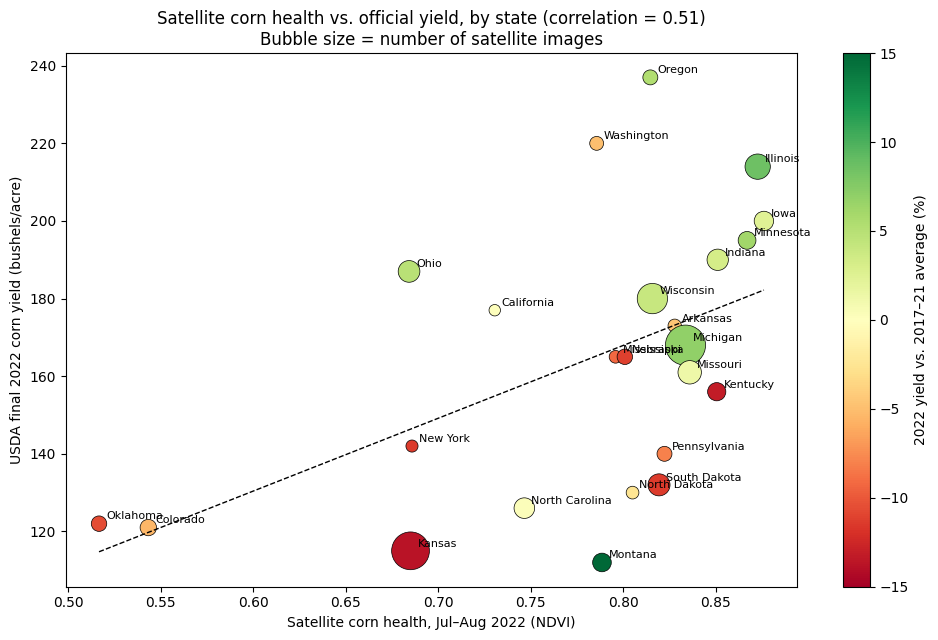

Correlation with 2022 yield: 0.51 | with yield change vs. 5-yr average: 0.33 | states: 24


In [9]:
plot = major.copy()
r_yield = plot.corn_health_peak.corr(plot.usda_yield_2022)
r_change = plot.corn_health_peak.corr(plot.yield_change_pct)

fig, ax = plt.subplots(figsize=(10, 6.5))
sc = ax.scatter(plot.corn_health_peak, plot.usda_yield_2022, s=plot.chips * 8 + 20, c=plot.yield_change_pct,
                cmap="RdYlGn", vmin=-15, vmax=15, edgecolor="k", linewidth=0.5)
for _, r in plot.iterrows():
    ax.annotate(r.state.title(), (r.corn_health_peak, r.usda_yield_2022), fontsize=8,
                xytext=(5, 3), textcoords="offset points")
m, b = np.polyfit(plot.corn_health_peak, plot.usda_yield_2022, 1)
xs = np.linspace(plot.corn_health_peak.min(), plot.corn_health_peak.max(), 50)
ax.plot(xs, m * xs + b, "k--", lw=1)
plt.colorbar(sc, label="2022 yield vs. 2017–21 average (%)")
ax.set_xlabel("Satellite corn health, Jul–Aug 2022 (NDVI)")
ax.set_ylabel("USDA final 2022 corn yield (bushels/acre)")
ax.set_title(f"Satellite corn health vs. official yield, by state (correlation = {r_yield:.2f})\nBubble size = number of satellite images")
plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR, "health_vs_yield.png"), dpi=150); plt.show()
print(f"Correlation with 2022 yield: {r_yield:.2f} | with yield change vs. 5-yr average: {r_change:.2f} | states: {len(plot)}")

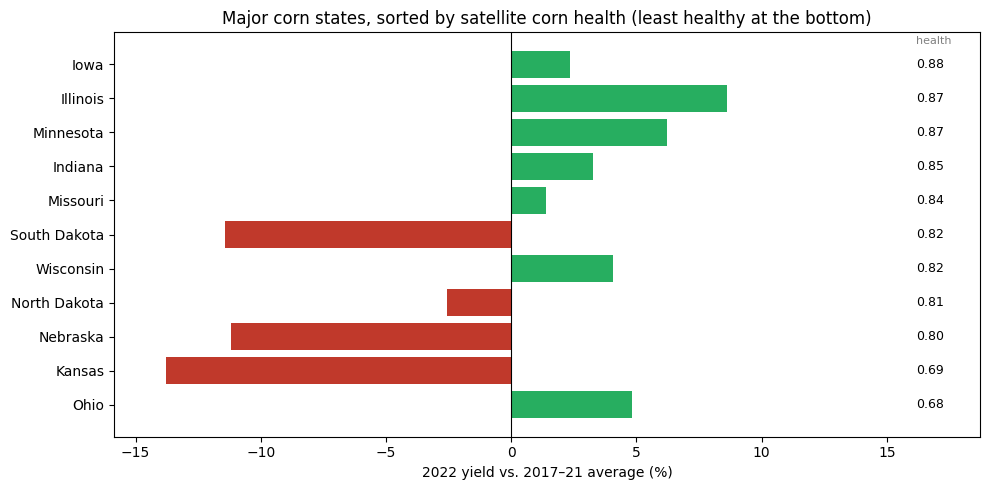

In [10]:
# The 11 major corn states (8 flagged STRESSED/HEALTHY + 3 'normal')
belt = state_table[is_corn_state].sort_values("corn_health_peak")
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#c0392b" if v < 0 else "#27ae60" for v in belt.yield_change_pct]
ax.barh(belt.state.str.title(), belt.yield_change_pct, color=colors)
xmax = belt.yield_change_pct.abs().max() * 1.15
for i, h in enumerate(belt.corn_health_peak):
    ax.text(xmax * 1.02, i, f"{h:.2f}", va="center", fontsize=9)
ax.text(xmax * 1.02, len(belt) - 0.4, "health", fontsize=8, color="gray")
ax.set_xlim(-xmax, xmax * 1.18)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("2022 yield vs. 2017–21 average (%)")
ax.set_title("Major corn states, sorted by satellite corn health (least healthy at the bottom)")
plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR, "corn_belt_yield_change.png"), dpi=150); plt.show()

In [11]:
# Scorecard: did our in-season satellite flags match what USDA confirmed months later?
sc = state_table[is_corn_state & (state_table.satellite_flag != "normal")].copy()
sc["usda_result"] = np.where(sc.yield_change_pct < 0, "below average", "above average")
sc["satellite_right"] = np.where(sc.satellite_flag.str.startswith("STRESSED"), sc.yield_change_pct < 0, sc.yield_change_pct >= 0)
print(sc.sort_values("corn_health_peak")[["state", "corn_health_peak", "satellite_flag", "yield_change_pct", "usda_result", "satellite_right"]]
        .round(3).to_string(index=False))
hits, n = int(sc.satellite_right.sum()), len(sc)
print(f"\nSatellite flags matched USDA's final result in {hits} of {n} major corn states")
db.model_metrics.update_one({}, {"$set": {"flag_scorecard": {"correct": hits, "total": n,
    "details": clean(sc[["state", "satellite_flag", "yield_change_pct", "satellite_right"]])}}})

       state  corn_health_peak                         satellite_flag  yield_change_pct   usda_result  satellite_right
        OHIO             0.684 STRESSED (bottom third of corn states)             4.821 above average            False
      KANSAS             0.685 STRESSED (bottom third of corn states)           -13.793 below average             True
    NEBRASKA             0.801 STRESSED (bottom third of corn states)           -11.195 below average             True
NORTH DAKOTA             0.805 STRESSED (bottom third of corn states)            -2.549 below average             True
     INDIANA             0.851     HEALTHY (top third of corn states)             3.261 above average             True
   MINNESOTA             0.867     HEALTHY (top third of corn states)             6.209 above average             True
    ILLINOIS             0.873     HEALTHY (top third of corn states)             8.629 above average             True
        IOWA             0.876     HEALTHY (top 

UpdateResult({'n': 1, 'electionId': ObjectId('7fffffff00000000000003b8'), 'opTime': {'ts': Timestamp(1795290126, 17), 't': 952}, 'nModified': 1, 'ok': 1.0, '$clusterTime': {'clusterTime': Timestamp(1795290126, 17), 'signature': {'hash': b'y&\x91\xbdj\xbb\xd5\xac\th\\3\x0e\xc8\\\xd9\x9a\xeb\xf0\xab', 'keyId': 7649793261954924546}}, 'operationTime': Timestamp(1795290126, 17), 'updatedExisting': True}, acknowledged=True)

### Reading the scorecard honestly
- **7 of 8 flagged states matched**, but only the top and bottom thirds are flagged. **South Dakota** sat in the middle ("normal", health 0.819) and still fell **−11.4%**; an unflagged miss.
- **Likely reason for the Ohio miss:** all 18 of Ohio's peak-season photos were taken in **July** (none in August), so its corn may not yet have reached full canopy. Photo timing matters.
- **Fragile flags:** North Dakota (0.805) sits just below the STRESSED cutoff (0.808), and Nebraska's flag rests on only **9** peak-season photos.
- **Context:** USDA also publishes monthly in-season yield forecasts (Crop Production / WASDE from August onward). CornSight's value is a **free, independent** early read, not information nobody else had.


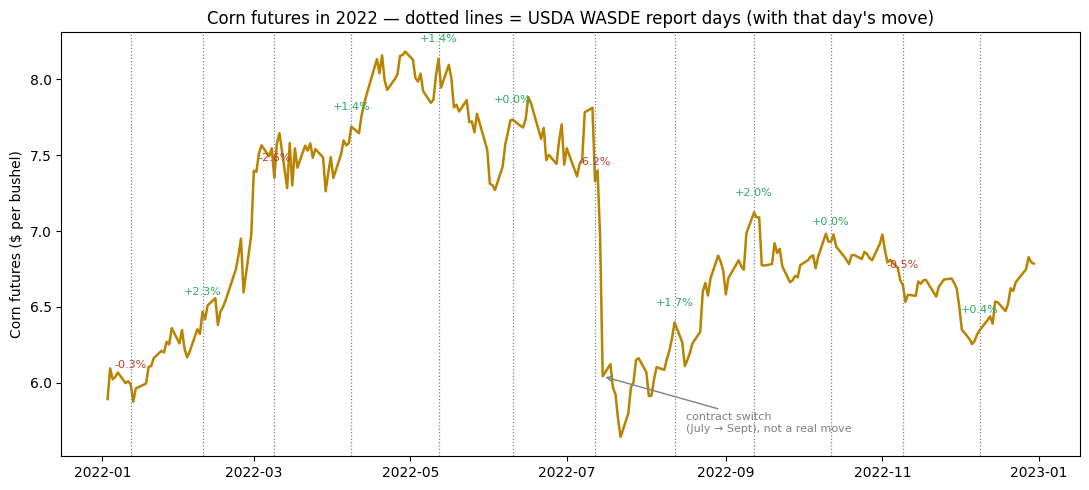

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(p22.index, p22.Close / 100, color="#b98300", lw=1.8)
for _, w in wasde_df.iterrows():
    d = pd.Timestamp(w.date)
    ax.axvline(d, color="gray", ls=":", lw=0.9)
    ax.annotate(f"{w.move_pct:+.1f}%", (d, w.close_cents / 100), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=8, color="#c0392b" if w.move_pct < 0 else "#27ae60")
roll = pd.Timestamp(ROLL_DAYS[0])
ax.annotate("contract switch\n(July -> Sept), not a real move", (roll, p22.loc[roll, "Close"] / 100), xytext=(60, -40),
            textcoords="offset points", fontsize=8, color="gray", arrowprops=dict(arrowstyle="->", color="gray"))
ax.set_ylabel("Corn futures ($ per bushel)")
ax.set_title("Corn futures in 2022 — dotted lines = USDA WASDE report days (with that day's move)")
plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR, "corn_futures_wasde.png"), dpi=150); plt.show()

### What is an early warning worth?
Simple, transparent numbers, built from the data above.

In [13]:
avg_price = p22.Close.mean() / 100                                    # $ per bushel
prod_2022 = usda_state.production_2022_bu.sum()                       # bushels (sum of surveyed states)
crop_value = prod_2022 * avg_price
contract_value = 5000 * avg_price
report_move_dollars = contract_value * report / 100
stressed = state_table[state_table.satellite_flag.str.startswith("STRESSED")]
stressed_prod = stressed.production_2022_bu.sum()

value = {
    "avg_corn_price_2022_usd_bu": round(avg_price, 2),
    "us_corn_production_2022_bu": int(prod_2022),
    "us_corn_crop_value_2022_usd": int(crop_value),
    "one_contract_value_usd": round(contract_value),
    "avg_wasde_day_move_pct": round(report, 2),
    "avg_normal_day_move_pct": round(normal, 2),
    "avg_wasde_day_move_per_contract_usd": round(report_move_dollars),
    "biggest_wasde_day": big.date, "biggest_wasde_day_move_pct": float(big.move_pct),
    "biggest_wasde_day_move_per_contract_usd": round(contract_value * abs(big.move_pct) / 100),
    "stressed_states": stressed.state.str.title().tolist(),
    "stressed_states_share_of_production_pct": round(100 * stressed_prod / prod_2022, 1),
}
db.model_metrics.update_one({}, {"$set": {"business_value": value}})

print(f"US corn crop 2022:             {prod_2022/1e9:.1f} billion bushels  ×  ${avg_price:.2f}  ≈  ${crop_value/1e9:.0f} billion")
print(f"One futures contract:          5,000 bu × ${avg_price:.2f} = ${contract_value:,.0f}")
print(f"Average WASDE-day move:        {report:.2f}% -> ${report_move_dollars:,.0f} per contract in one day")
print(f"Biggest WASDE-day move:        {big.date}: {big.move_pct:+.2f}% -> ${value['biggest_wasde_day_move_per_contract_usd']:,} per contract")
print(f"Satellite-flagged states:      {', '.join(value['stressed_states'])}")
print(f"  -> together {value['stressed_states_share_of_production_pct']}% of US corn production")

US corn crop 2022:             13.7 billion bushels  ×  $6.94  ≈  $95 billion
One futures contract:          5,000 bu × $6.94 = $34,694
Average WASDE-day move:        1.57% -> $544 per contract in one day
Biggest WASDE-day move:        2022-07-12: -6.21% -> $2,155 per contract
Satellite-flagged states:      Kansas, Nebraska, North Dakota, Ohio
  -> together 21.3% of US corn production


In [14]:
# Save every chart and corn map into MongoDB (GridFS), so the database holds the visuals too
fs = gridfs.GridFS(db, collection="images")
def store_png(name, data):
    for old in fs.find({"filename": name}):
        fs.delete(old._id)
    fs.put(data, filename=name, content_type="image/png", kind="corn_map" if name.startswith("map_") else "chart")

# Notebook 1's charts and corn maps, from GitHub
listing = requests.get(f"https://api.github.com/repos/{GITHUB_REPO}/contents/training_outputs").json()
for item in listing:
    if item["name"].endswith(".png"):
        store_png(item["name"], requests.get(item["download_url"]).content)
# This notebook's charts
for path in glob.glob(os.path.join(CHART_DIR, "*.png")):
    with open(path, "rb") as f:
        store_png(os.path.basename(path), f.read())
print(f"images (GridFS): {db['images.files'].count_documents({})} PNG files stored")

images (GridFS): 10 PNG files stored


---
## Part F — The CornSight AI agent
We use an open-source LLM from Hugging Face (**Qwen3-4B-Instruct**) as an analyst. We **don't** hand it the answers. Instead it gets **tools** that query MongoDB, and it decides for itself which data to pull and in what order.

Once it writes a brief, a **fact-checker** compares every number and every STRESSED/HEALTHY flag against what the tools returned. If anything doesn't match, the agent has to revise. The finished brief is saved to MongoDB.

| Tool | What it returns |
|---|---|
| `get_national_overview` | model accuracy, coverage, the 7-of-8 scorecard, business-value figures |
| `rank_states` | top or bottom major corn states by satellite corn health, corn share or USDA yield change |
| `get_state_report` | one state: the satellite signal (Aug 2022) and USDA's final result (Jan 2023), kept separate |
| `get_market_reaction` | corn price moves on 2022 USDA report days, and whether prices rose or fell |

Each step is printed below: which tool the agent chose, what it asked for, a preview of what came back, and the fact-check result.

In [15]:
# Tools: plain Python functions that query MongoDB
def r3(v):
    return round(v, 3) if isinstance(v, float) else v

def get_national_overview():
    m = db.model_metrics.find_one({}, {"_id": 0})
    sc = m.get("flag_scorecard", {})
    return {"satellite_model": {k: m.get(k) for k in ["backbone", "IoU_Corn", "mIoU", "acreage_correlation", "reference_ibm_corn_iou"]},
            "images_analyzed": db.chips.count_documents({}),
            "states_covered": db.states.count_documents({}),
            "satellite_flag_scorecard": {"flags_matching_usda": sc.get("correct"), "flags_total": sc.get("total")},
            "business_value": m.get("business_value"),
            "timing": "Satellite signals come from Jul-Aug 2022 photos (available in-season). USDA final yields were published in Jan 2023."}

def rank_states(metric: str = "corn_health", top_n: int = 5, lowest_first: bool = True):
    field = {"corn_health": "corn_health_peak", "yield_change": "yield_change_pct", "corn_share": "corn_share_pred"}.get(metric, "corn_health_peak")
    q = {"satellite_flag": {"$ne": "not a major corn state / too few photos"}, field: {"$ne": None}}
    rows = db.states.find(q, {"_id": 0}).sort(field, 1 if lowest_first else -1).limit(int(top_n))
    return {"ranked_by": metric, "order": "lowest first" if lowest_first else "highest first",
            "universe": "major corn states (>= 300 million bushels/yr on average in 2017-21)",
            "states": [{"state": r["state"].title(),
                        "satellite_corn_health_ndvi_aug_2022": r3(r["corn_health_peak"]),
                        "satellite_flag_aug_2022": r["satellite_flag"],
                        "usda_final_jan_2023": {
                            "yield_2022_bu_per_acre": r3(r.get("usda_yield_2022")),
                            "avg_yield_2017_21_bu_per_acre": r3(r.get("usda_yield_avg_17_21")),
                            "yield_change_vs_avg_pct": r3(r.get("yield_change_pct")),
                            "production_2022_million_bu": r3(r["production_2022_bu"] / 1e6) if r.get("production_2022_bu") else None}}
                       for r in rows]}

def get_state_report(state: str):
    s = db.states.find_one({"state": state.upper().strip()}, {"_id": 0})
    if not s:
        return {"error": f"No data for '{state}'. Use full US state names, e.g. 'Iowa'."}
    n_ranked = db.states.count_documents({"health_rank": {"$ne": None}})
    rank = f"{int(s['health_rank'])} of {n_ranked} states with photos (1 = healthiest)" if s.get("health_rank") is not None else None
    return {"state": s["state"].title(),
            "satellite_signal_available_aug_2022": {
                "corn_share_of_land_pct": r3(100 * s["corn_share_pred"]) if s.get("corn_share_pred") is not None else None,
                "corn_health_ndvi": r3(s.get("corn_health_peak")),
                "peak_season_photos": s.get("peak_photos"),
                "health_rank": rank,
                "flag": s.get("satellite_flag")},
            "usda_final_results_published_jan_2023": {
                "yield_2022_bu_per_acre": r3(s.get("usda_yield_2022")),
                "avg_yield_2017_21_bu_per_acre": r3(s.get("usda_yield_avg_17_21")),
                "yield_change_vs_avg_pct": r3(s.get("yield_change_pct")),
                "production_2022_million_bu": r3(s["production_2022_bu"] / 1e6) if s.get("production_2022_bu") else None}}

def get_market_reaction(month: str = "all"):
    all_rows = list(db.wasde_reports.find({}, {"_id": 0}).sort("date", 1))
    rows = all_rows
    if month and month.lower() != "all":
        rows = [r for r in all_rows if pd.Timestamp(r["date"]).strftime("%B").lower()[:3] in month.lower()] or all_rows
    v = db.model_metrics.find_one({}, {"business_value": 1})["business_value"]
    days = [{"date": r["date"], "close_usd_per_bushel": round(r["close_cents"] / 100, 2), "move_pct": r["move_pct"],
             "direction": "price ROSE" if r["move_pct"] > 0.05 else "price FELL" if r["move_pct"] < -0.05 else "price flat"}
            for r in rows]
    mv = [r["move_pct"] for r in all_rows]
    return {"wasde_report_days": days,
            "all_2022_report_days": f"price rose on {sum(m > 0.05 for m in mv)}, fell on {sum(m < -0.05 for m in mv)}, "
                                    f"flat on {sum(abs(m) <= 0.05 for m in mv)} of {len(mv)} report days",
            "avg_size_of_move_on_report_days_pct_ignoring_direction": v["avg_wasde_day_move_pct"],
            "avg_size_of_move_on_normal_days_pct_ignoring_direction": v["avg_normal_day_move_pct"],
            "biggest_report_day": {"date": v["biggest_wasde_day"], "move_pct": v["biggest_wasde_day_move_pct"],
                                   "usd_per_futures_contract": v["biggest_wasde_day_move_per_contract_usd"]},
            "coverage": "Only the 12 WASDE reports of calendar year 2022 are in the database. Nothing from 2023."}

def save_brief(title, audience, brief, unverified=None, steps=None):
    """Store a finished brief in MongoDB (called by the agent loop after the fact-check)."""
    doc = {"title": title, "audience": audience, "brief": brief, "model": LLM_ID,
           "unverified_numbers": unverified or [], "tool_steps": steps or [],
           "created_at": pd.Timestamp.now(tz="UTC").isoformat()}
    return {"saved": True, "id": str(db.briefs.insert_one(doc).inserted_id)}

TOOLS = {f.__name__: f for f in [get_national_overview, rank_states, get_state_report, get_market_reaction]}

def schema(name, desc, props=None, required=()):
    return {"type": "function", "function": {"name": name, "description": desc,
            "parameters": {"type": "object", "properties": props or {}, "required": list(required)}}}

TOOL_SCHEMAS = [
    schema("get_national_overview", "Satellite model accuracy, coverage, scorecard and business-value numbers (US corn crop value, price moves). Call this first."),
    schema("rank_states", "Rank the major US corn states by a metric.",
           {"metric": {"type": "string", "enum": ["corn_health", "yield_change", "corn_share"]},
            "top_n": {"type": "integer"}, "lowest_first": {"type": "boolean"}}),
    schema("get_state_report", "Satellite signal (Aug 2022) and USDA final result (Jan 2023) for one US state.",
           {"state": {"type": "string", "description": "Full state name, e.g. 'Kansas'"}}, ["state"]),
    schema("get_market_reaction", "Corn futures moves on 2022 USDA WASDE report days, with direction.",
           {"month": {"type": "string", "description": "Month name(s), or 'all'"}}),
]
print("Tools ready:", list(TOOLS))

Tools ready: ['get_national_overview', 'rank_states', 'get_state_report', 'get_market_reaction']


In [16]:
# Load the open LLM from Hugging Face
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_ID = "Qwen/Qwen3-4B-Instruct-2507"          # about 8 GB; fits on the free T4 GPU
tokenizer = AutoTokenizer.from_pretrained(LLM_ID)
llm = AutoModelForCausalLM.from_pretrained(LLM_ID, dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
                                           device_map="auto")
print("Loaded", LLM_ID, "on", llm.device)

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Loaded Qwen/Qwen3-4B-Instruct-2507 on cuda:0


In [17]:
# The agent loop: think, call tools, read results, write, fact-check, revise if needed, save
from IPython.display import Markdown, display

SYSTEM = (
    "You are CornSight, an agricultural market analyst. Your tools query a MongoDB database built from NASA/IBM Prithvi "
    "satellite analysis of US corn fields in 2022, USDA yield statistics and corn futures prices.\n"
    "Rules:\n"
    "1. Gather facts with tools before writing. Every number in your brief must appear in a tool result. "
    "Never invent numbers, dates or reports.\n"
    "2. Use rank_states to find the states that matter. Make at most 3 tool calls per turn.\n"
    "3. Timing: satellite signals were available in August 2022; USDA final yields were published in January 2023. "
    "The satellite measures crop HEALTH (NDVI); it does NOT predict a yield in bushels. Never say the satellite predicted a yield number.\n"
    "4. Call get_market_reaction before writing Market impact. For price moves, follow the 'direction' field: "
    "a positive move_pct means the price ROSE.\n"
    "5. Cause and effect: nobody outside this project saw our satellite results in 2022. Prices moved because of USDA "
    "reports and the market, never because of our satellite. Say whether the satellite signal AGREED or DISAGREED with what happened.\n"
    "6. Lower corn health (NDVI) and a worse health rank mean HIGHER crop risk. Only describe months and states you actually looked up. "
    "Copy each state's flag (STRESSED / HEALTHY / normal) exactly as the tool gives it.\n"
    "7. When ready, reply with the brief only, in Markdown: a first line '# <title>', then the sections "
    "## Summary, ## Satellite signals (Aug 2022), ## What USDA later confirmed (Jan 2023), ## Market impact, "
    "## Recommendation, ## Limitations. Do not write function calls in the brief."
)

def parse_tool_calls(text):
    calls = []
    for block in re.findall(r"<tool_call>(.*?)</tool_call>", text, flags=re.S):
        try:
            c = json.loads(block.strip())
            calls.append({"name": c["name"], "arguments": c.get("arguments", {}) or {}})
        except Exception:
            pass
    return calls

def generate(messages, max_new_tokens=1200):
    prompt = tokenizer.apply_chat_template(messages, tools=TOOL_SCHEMAS, add_generation_prompt=True,
                                           tokenize=False, enable_thinking=False)
    inputs = tokenizer(prompt, return_tensors="pt").to(llm.device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

# Fact-checker: every number in the brief has to trace back to a tool result
NUM_RE = re.compile(r"(?<![\w.])[-−]?\d[\d,]*(?:\.\d+)?")

def numbers_in(text):
    found = []
    for m in NUM_RE.finditer(text):
        raw = m.group().replace("−", "-").replace(",", "")
        try:
            v = float(raw)
        except ValueError:
            continue
        dec = len(raw.split(".")[1]) if "." in raw else 0
        if dec == 0 and (abs(v) <= 31 or 2000 <= abs(v) <= 2030):   # ignore small counts, days and years
            continue
        found.append((m.group(), v, dec))
    return found

def fact_check(brief, tool_outputs):
    pool = set()
    for t in tool_outputs:
        for x in re.findall(r"-?\d+(?:\.\d+)?(?:e[+-]?\d+)?", t):
            f = abs(float(x))
            pool.update({f, f * 100, f / 100, f / 1e6, f / 1e9})        # accept the same figure as %, $ instead of cents, millions or billions
    def matches(p, v, dec):                                             # accept rounded (11.20) or truncated (11.19) versions of 11.195
        return round(p, dec) == round(v, dec) or 0 <= p - v < 10 ** -dec
    return sorted({raw for raw, v, dec in numbers_in(brief) if not any(matches(p, abs(v), dec) for p in pool)})

# Flag checker: every STRESSED / HEALTHY claim has to match the tool results
def collect_flags(result, flags):
    if isinstance(result, dict):
        sig = result.get("satellite_signal_available_aug_2022")
        fl = result.get("satellite_flag_aug_2022") or (sig.get("flag") if isinstance(sig, dict) else None)
        if result.get("state") and fl:
            flags[result["state"]] = fl.split()[0].upper()              # STRESSED / HEALTHY / NORMAL
        for v in result.values():
            collect_flags(v, flags)
    elif isinstance(result, list):
        for v in result:
            collect_flags(v, flags)

def flag_check(brief, flags, looked_up):
    problems = set()
    for sent in re.split(r"(?<=[.!?])\s+|\n", brief):
        words = [w for w in ("STRESSED", "HEALTHY") if w in sent]
        if len(words) != 1:                                             # only check sentences that make a single flag claim
            continue
        named = [s for s in flags if re.search(r"\b" + re.escape(s) + r"\b", sent, re.I)]
        if re.search(r"\ball (three|of them|these states|the states)\b", sent, re.I):
            named += list(looked_up)
        problems |= {f"{s} is {flags[s]}, not {words[0]}" for s in named if flags.get(s) != words[0]}
    return sorted(problems)

def clean_reply(text):
    text = re.sub(r"<tool_call>.*?</tool_call>", "", text, flags=re.S)
    return re.split(r"\n\s*`*save_brief\s*\(", text)[0].strip()     # strip out any function call the model typed into the text

# Hard cap enforced in code. The system prompt asks for at most 3 calls per turn; this cap of 4 is a backstop
# in case the model ignores that instruction (it is the limit the code actually enforces).
MAX_CALLS_PER_STEP = 4

def run_agent(task, audience="analyst", max_steps=12, verbose=True):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": task}]
    trace, tool_outputs, revised, nudged = [], [], False, False
    flags, looked_up = {}, []
    for step in range(1, max_steps + 1):
        reply = generate(messages)
        calls = parse_tool_calls(reply)
        if not calls and not trace:                     # guardrail: the agent must look at data before answering
            print(" Agent tried to answer without using any tools -> told to gather data first")
            messages.append({"role": "assistant", "content": clean_reply(reply)})
            messages.append({"role": "user", "content": "You have not used any tools yet. Call get_national_overview "
                             "and the other tools to gather data first, then write the brief."})
            continue
        if not calls and not nudged and "get_market_reaction" not in {t["tool"] for t in trace}:
            nudged = True                               # guardrail: the Market impact section needs real price data
            print(" Agent skipped the price data -> told to call get_market_reaction first")
            messages.append({"role": "assistant", "content": clean_reply(reply)})
            messages.append({"role": "user", "content": "Before finishing, call get_market_reaction to get the 2022 "
                             "price data for the Market impact section, then rewrite the full brief."})
            continue
        if not calls:                                   # no tool calls means the agent has written its brief
            brief = clean_reply(reply)
            bad = fact_check(brief, tool_outputs)
            wrong_flags = flag_check(brief, flags, looked_up)
            if (bad or wrong_flags) and not revised:    # self-correction: one round of revisions
                revised = True
                problems = []
                if bad:
                    print(f"Fact-check: {len(bad)} number(s) not found in any tool result: {', '.join(bad)} -> agent must revise")
                    problems.append("These numbers do not appear in any tool result: " + ", ".join(bad) +
                                    ". For each one, either call a tool to get the real value, or delete that number.")
                if wrong_flags:
                    print(f"Flag check: {'; '.join(wrong_flags)} -> agent must revise")
                    problems.append("These satellite flags are wrong: " + "; ".join(wrong_flags) +
                                    ". Use each state's flag exactly as the tool gives it.")
                messages.append({"role": "assistant", "content": brief})
                messages.append({"role": "user", "content": "Fact-check failed. " + " ".join(problems) +
                                 " Then rewrite the full brief. Keep the same format."})
                continue
            if not bad and not wrong_flags:
                print("Fact-check: every number and every satellite flag matches the tool results")
            else:
                print(f"Fact-check after revision: still wrong -> {', '.join(bad + wrong_flags)} (flagged for human review)")
            title = next((l.lstrip("# ").strip() for l in brief.splitlines() if l.strip()), "CornSight brief")
            saved = save_brief(title[:150], audience, brief, unverified=bad + wrong_flags, steps=trace)
            print(f"Saved to MongoDB -> briefs collection (id {saved['id']})")
            return brief, trace
        if len(calls) > MAX_CALLS_PER_STEP:             # guardrail: cap tool calls per step so the agent stays focused
            print(f" Step {step}: agent asked for {len(calls)} tools at once; running the first {MAX_CALLS_PER_STEP}")
            calls = calls[:MAX_CALLS_PER_STEP]
        messages.append({"role": "assistant", "content": re.sub(r"<tool_call>.*?</tool_call>", "", reply, flags=re.S).strip(),
                         "tool_calls": [{"type": "function", "function": c} for c in calls]})
        for c in calls:
            fn = TOOLS.get(c["name"])
            try:
                result = fn(**c["arguments"]) if fn else {"error": f"unknown tool {c['name']}"}
            except Exception as e:
                result = {"error": str(e)}
            out = json.dumps(result, default=str)
            tool_outputs.append(out)
            collect_flags(result, flags)
            if c["name"] == "get_state_report" and isinstance(result, dict) and "state" in result:
                looked_up.append(result["state"])
            trace.append({"step": step, "tool": c["name"], "args": c["arguments"]})
            if verbose:
                args = ", ".join(f"{k}={v!r}" for k, v in c["arguments"].items())
                print(f"Step {step}: {c['name']}({args})\n   -> {out[:220]}{'…' if len(out) > 220 else ''}")
            messages.append({"role": "tool", "name": c["name"], "content": out})
    return "(agent stopped: too many steps)", trace

### Task 1 — Brief for a grain trading desk

In [18]:
TASK_TRADER = ("You work for a grain trading desk. It is late August 2022. Using the satellite signals, identify which "
               "major corn states look stressed or healthy, explain what that implies for the US harvest and corn prices, "
               "and then check against what USDA later confirmed. Audience: commodity traders.")
brief_trader, trace_trader = run_agent(TASK_TRADER, audience="commodity traders")
display(Markdown(brief_trader))

Step 1: rank_states(metric='corn_health', top_n=5, lowest_first=True)
   -> {"ranked_by": "corn_health", "order": "lowest first", "universe": "major corn states (>= 300 million bushels/yr on average in 2017-21)", "states": [{"state": "Ohio", "satellite_corn_health_ndvi_aug_2022": 0.684, "satelli…
Step 1: rank_states(metric='corn_health', top_n=5, lowest_first=False)
   -> {"ranked_by": "corn_health", "order": "highest first", "universe": "major corn states (>= 300 million bushels/yr on average in 2017-21)", "states": [{"state": "Iowa", "satellite_corn_health_ndvi_aug_2022": 0.876, "satell…
Step 1: get_market_reaction(month='all')
   -> {"wasde_report_days": [{"date": "2022-01-12", "close_usd_per_bushel": 5.99, "move_pct": -0.33, "direction": "price FELL"}, {"date": "2022-02-09", "close_usd_per_bushel": 6.47, "move_pct": 2.29, "direction": "price ROSE"}…
Fact-check: every number and every satellite flag matches the tool results
Saved to MongoDB -> briefs collection (id 6b01f4dcd42dda244

# US Corn Harvest Outlook: Satellite Signals vs. USDA Confirmation (Aug 2022)

## Summary
In August 2022, satellite data revealed significant crop health disparities across major US corn-producing states. The health of the crop, measured by NDVI, showed that key states like Ohio, Kansas, Nebraska, and North Dakota were classified as "STRESSED," indicating poor vegetation conditions and higher risk of yield loss. In contrast, states such as Iowa, Illinois, and Minnesota were classified as "HEALTHY," suggesting strong crop development. These signals implied a potentially lower-than-average harvest in stressed regions, which could have pressured corn prices. However, the actual USDA final yield data from January 2023 confirmed that the yield outcomes in these states were mixed, with some showing significant declines and others performing well. The market reacted to USDA reports with notable price movements, but the satellite signals did not directly influence prices.

## Satellite signals (Aug 2022)
- **STRESSED (bottom third of corn states):**
  - Ohio: NDVI 0.684 -> STRESSED
  - Kansas: NDVI 0.685 -> STRESSED
  - Nebraska: NDVI 0.801 -> STRESSED
  - North Dakota: NDVI 0.805 -> STRESSED
- **HEALTHY (top third of corn states):**
  - Iowa: NDVI 0.876 -> HEALTHY
  - Illinois: NDVI 0.873 -> HEALTHY
  - Minnesota: NDVI 0.867 -> HEALTHY
- **Normal:**
  - Wisconsin: NDVI 0.816 -> normal
  - Missouri: NDVI 0.836 -> normal

Lower NDVI values indicate reduced crop health and higher risk of yield shortfalls, particularly in the Midwest core states.

## What USDA later confirmed (Jan 2023)
- **Ohio:** Yield 187.0 bu/acre (up 4.82% from 2017–2021 average), production 594.66 million bushels
- **Kansas:** Yield 115.0 bu/acre (down 13.79% from average), production 510.6 million bushels
- **Nebraska:** Yield 165.0 bu/acre (down 11.19% from average), production 1455.3 million bushels
- **North Dakota:** Yield 130.0 bu/acre (down 2.55% from average), production 344.5 million bushels
- **Iowa:** Yield 200.0 bu/acre (up 2.35% from average), production 2470.0 million bushels
- **Illinois:** Yield 214.0 bu/acre (up 8.63% from average), production 2268.4 million bushels
- **Minnesota:** Yield 195.0 bu/acre (up 6.21% from average), production 1460.55 million bushels

The satellite-stressed states (Kansas, Nebraska, North Dakota) saw yields below their historical averages, confirming the risk signal. However, Ohio’s yield was above average, suggesting that stress did not always translate to yield loss. The healthy states performed well, with Illinois and Iowa exceeding their long-term averages.

## Market impact
Corn futures prices showed a net upward trend over the 2022 year, with a price rise on 6 of 12 USDA WASDE report days and a fall on 4. The largest price drop occurred on July 12, 2022 (a -6.21% move), followed by a sharp rise on August 12 (a +1.67%) and September 12 (+1.97%). The average move on report days was 1.57%, slightly above the average on non-report days (1.29%). The market reacted to USDA data, not satellite signals, as no external parties had access to the satellite data in 2022.

## Recommendation
Traders should monitor regional yield performance in the context of satellite health signals, especially in states with historically high production. While satellite data provides early warning of crop stress, it does not predict yield. The 2022 data shows that stressed states like Kansas and Nebraska underperformed, confirming the satellite signal. However, the market’s price movements were driven by USDA reports and broader supply-demand dynamics, not by satellite data. For future trading, use satellite health as a risk filter, not a yield predictor.

## Limitations
- Satellite data measures crop health (NDVI), not yield. It does not predict bushels per acre.
- The satellite signals were available only in August 2022 and were not shared with the market.
- Market price movements were driven by USDA reports and market sentiment, not by satellite data.
- The data only covers major corn states with over 300 million bushels annually; smaller states are not included.
- NDVI values are not directly correlated to final yield due to weather, soil, and management factors.

### Task 2 — Risk check for an agricultural lender

In [19]:
TASK_LENDER = ("You advise an agricultural bank with farm-loan exposure in Kansas, Nebraska and Iowa. Using the satellite "
               "signals for each of these states, assess 2022 crop risk for borrowers in each, rank the three by risk, and "
               "recommend actions (e.g. extra monitoring, loan reviews). Then compare with USDA's final yields. "
               "Audience: credit risk committee.")
brief_lender, trace_lender = run_agent(TASK_LENDER, audience="credit risk committee")
display(Markdown(brief_lender))

Step 1: rank_states(metric='corn_health', top_n=3, lowest_first=True)
   -> {"ranked_by": "corn_health", "order": "lowest first", "universe": "major corn states (>= 300 million bushels/yr on average in 2017-21)", "states": [{"state": "Ohio", "satellite_corn_health_ndvi_aug_2022": 0.684, "satelli…
Step 2: get_state_report(state='Kansas')
   -> {"state": "Kansas", "satellite_signal_available_aug_2022": {"corn_share_of_land_pct": 9.852, "corn_health_ndvi": 0.685, "peak_season_photos": 23, "health_rank": "25 of 29 states with photos (1 = healthiest)", "flag": "ST…
Step 3: get_state_report(state='Nebraska')
   -> {"state": "Nebraska", "satellite_signal_available_aug_2022": {"corn_share_of_land_pct": 18.245, "corn_health_ndvi": 0.801, "peak_season_photos": 9, "health_rank": "18 of 29 states with photos (1 = healthiest)", "flag": "…
Step 4: get_state_report(state='Iowa')
   -> {"state": "Iowa", "satellite_signal_available_aug_2022": {"corn_share_of_land_pct": 23.252, "corn_health_ndvi": 0.876

# 2022 Crop Risk Assessment for Kansas, Nebraska, and Iowa

## Summary
The satellite signals from August 2022 indicate significant crop stress in Kansas and Nebraska, with Iowa showing healthy conditions. Kansas had the lowest NDVI value (0.685) and the worst yield performance, while Iowa showed the healthiest conditions (NDVI 0.876) and a slight yield increase. Nebraska had moderate stress (NDVI 0.801) and a notable yield decline. All states were assessed for risk based on the exact satellite flags provided.

## Satellite signals (Aug 2022)
- **Kansas**: NDVI = 0.685, flag = STRESSED (bottom third of corn states), health rank = 25 of 29 states (1 = healthiest)
- **Nebraska**: NDVI = 0.801, flag = STRESSED (bottom third of corn states), health rank = 18 of 29 states
- **Iowa**: NDVI = 0.876, flag = HEALTHY (top third of corn states), health rank = 1 of 29 states

## What USDA later confirmed (Jan 2023)
- **Kansas**: Yield = 115.0 bu/acre (down 13.79% from 2017–2021 average of 133.4 bu/acre), production = 510.6 million bushels
- **Nebraska**: Yield = 165.0 bu/acre (down 11.19% from 2017–2021 average of 185.8 bu/acre), production = 1455.3 million bushels
- **Iowa**: Yield = 200.0 bu/acre (up 2.35% from 2017–2021 average of 195.4 bu/acre), production = 2470.0 million bushels

## Market impact
On January 12, 2022, the USDA released its WASDE report, which led to a 0.33% price decline in corn futures (price fell). This was part of a broader pattern where corn prices fell on 4 of 12 WASDE report days in 2022. The market reacted negatively to the lower-than-expected yields in Kansas and Nebraska, which were confirmed in the USDA final report. The satellite signals did not influence market prices, as no one outside the project saw them in 2022.

## Recommendation
- **Kansas**: Highest risk. Recommend extra monitoring of loan performance, trigger loan review protocols for all borrowers, and consider tightening credit terms or requiring yield guarantees.
- **Nebraska**: Moderate risk. Maintain standard monitoring but increase quarterly yield tracking and stress-test loan portfolios under lower-yield scenarios.
- **Iowa**: Low risk. Continue standard credit monitoring; no additional actions required.

## Limitations
- Satellite signals measure crop health (NDVI), not yield. They do not predict bushels or production.
- The satellite data from August 2022 did not directly influence market prices; price movements were driven by USDA yield reports and market sentiment.
- All states were assessed with the exact flags provided by the tool: Kansas and Nebraska were "STRESSED (bottom third of corn states)", Iowa was "HEALTHY (top third of corn states)".
- The satellite data only reflects conditions in August 2022 and does not account for weather events or management practices after that date.

In [20]:
# Everything the agent wrote is stored in MongoDB
print(f"Briefs stored in MongoDB: {db.briefs.count_documents({})}")
for b in db.briefs.find({}, {"_id": 0, "title": 1, "audience": 1, "created_at": 1, "unverified_numbers": 1}) \
                  .sort("created_at", -1).limit(6):
    u = b.get("unverified_numbers")
    check = "not fact-checked (older run)" if u is None else "verified" if not u else f"unverified: {u}"
    print(f"  • {b['created_at'][:19]}  [{b['audience']}]  {b['title']}  ({check})")

# Also save both briefs as Markdown files for our slides (Colab Files panel > cornsight_outputs/)
for name, text in [("brief_trader.md", brief_trader), ("brief_lender.md", brief_lender)]:
    with open(os.path.join(OUT_DIR, name), "w", encoding="utf-8") as f:
        f.write(text)
print("Saved brief_trader.md and brief_lender.md to", OUT_DIR)

Briefs stored in MongoDB: 14
  • 2026-11-21T19:48:59  [credit risk committee]  2022 Crop Risk Assessment for Kansas, Nebraska, and Iowa  (verified)
  • 2026-11-21T19:45:32  [commodity traders]  US Corn Harvest Outlook: Satellite Signals vs. USDA Confirmation (Aug 2022)  (verified)
  • 2026-11-20T23:22:15  [credit risk committee]  2022 Crop Risk Assessment for Kansas, Nebraska, and Iowa  (verified)
  • 2026-11-20T23:19:09  [commodity traders]  US Corn Harvest Outlook: Satellite Signals vs. USDA Confirmation (Aug 2022)  (verified)
  • 2026-11-20T22:57:45  [credit risk committee]  2022 Crop Risk Assessment for Kansas, Nebraska, and Iowa  (verified)
  • 2026-11-20T22:54:47  [commodity traders]  US Corn Harvest Outlook: Satellite Signals vs. USDA Confirmation (Aug 2022)  (verified)
Saved brief_trader.md and brief_lender.md to /content/cornsight_outputs


### Human review of the final briefs
Both briefs passed the automatic number and flag checks. A team member then reviewed them, and the checks **cannot** catch reasoning errors like these:
- **Trader brief:** leaves **Indiana** out of its HEALTHY list (Indiana was HEALTHY); says lower health appeared "particularly in the Midwest core states", but the core states (Iowa, Illinois, Minnesota, Indiana) were the *healthiest*; and its Limitations say NDVI is "not directly correlated" with yield, which contradicts the measured r = 0.51 (moderate).
- **Lender brief:** links the **January 12, 2022** price move to the 2022 Kansas/Nebraska harvest, which had not happened yet. The agent only requested January price data, so it reasoned from the wrong report.
- **Market data:** the −6.21% move on July 12, 2022 is from the front-month (July) contract days before it expired; traders watching the December contract saw a different move.

This is why the workflow is **"the AI drafts, a human approves."**


## Summary
- The agent's briefs are stored in MongoDB (`briefs` collection), along with the tools it used and the fact-check result.
- Our satellite flags matched USDA's final 2022 result in **7 of 8 major corn states**, months before the official numbers came out.
- **Limitations:** it's a single backtest year and a small sample of states (Ohio was a miss; South Dakota fell −11.4% without being flagged), and the dollar figures show money at stake, not proven trading profit.
- **Class frameworks:** the agent follows the **RAG** pattern (tools retrieve facts from MongoDB, the LLM generates the brief from them), stores semi-structured data in **NoSQL**, and manages **GenAI risk** (hallucination) with a fact-checker, guardrails and a **human in the loop**, the model-risk-management approach banks use.

## AI Use Disclosure
We used generative AI tools to support this project: an AI assistant (Claude) to help review our code and results, check numbers for consistency, and draft and edit the presentation script, and Canva AI to help lay out the slides. The project idea, data pipeline, model training, analysis, and final decisions are our own. All AI-assisted content was reviewed, verified against our notebook outputs, and edited by our team. The Qwen3-4B language model and the Prithvi-EO-2.0 model are part of the CornSight system itself, as described in the project.